# Домашнее задание 10

**Тема 10.** Корреляция и корреляционный анализ
**Данные:** `water.csv` — 61 город Англии и Уэльса, смертность на 100 000 населения
и концентрация кальция в питьевой воде; города делятся на северные и южные
**Структура:** подготовка → функции → задание 1 (все города) → задание 2 (север и юг) → выводы

**Вопрос 1.** Есть ли связь между жёсткостью воды и средней годовой смертностью?
**Вопрос 2.** Сохраняется ли эта зависимость для северных и южных городов по отдельности?

Для каждого набора данных строю точечный график, считаю корреляции Пирсона и Спирмена,
строю линейную регрессию, считаю коэффициент детерминации и вывожу график остатков.


## Подготовка

Файл `water.csv` лежит в этой же папке. Столбец `rownames` — служебный номер строки,
он не нужен для анализа, поэтому удаляю его при загрузке.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

pd.set_option("display.width", 160)


## Функции

* `load_water` — загрузка данных без служебного столбца;
* `by_region` — выборка по региону (север / юг / все города);
* `correlations` — коэффициенты Пирсона и Спирмена с p-value;
* `fit_regression` — линейная регрессия методом наименьших квадратов;
* `determination` — коэффициент детерминации;
* `residuals` — остатки модели;
* `analyze` — все пять шагов для одного набора данных;
* `plot_scatter`, `plot_residuals` — графики.


In [2]:
def load_water(file_path):
    """Загружаю данные и убираю служебный столбец с номером строки."""
    if not Path(file_path).exists():
        raise FileNotFoundError(f"Нет файла {file_path}: положите его рядом с ноутбуком.")
    return pd.read_csv(file_path).drop(columns=["rownames"])


def by_region(data, region=None):
    """Выборка по региону: None — все города, иначе 'North' или 'South'."""
    if region is None:
        return data
    return data[data["location"] == region].copy()


def correlations(data):
    """Коэффициенты Пирсона и Спирмена для пары жёсткость — смертность."""
    pearson = stats.pearsonr(data["hardness"], data["mortality"])
    spearman = stats.spearmanr(data["hardness"], data["mortality"])
    return {
        "pearson_r": pearson.statistic,
        "pearson_p": pearson.pvalue,
        "spearman_rho": spearman.statistic,
        "spearman_p": spearman.pvalue,
    }


def fit_regression(data):
    """Линейная регрессия mortality = a + b * hardness методом наименьших квадратов."""
    result = stats.linregress(data["hardness"], data["mortality"])
    return {
        "intercept": result.intercept,
        "slope": result.slope,
        "r": result.rvalue,
        "p": result.pvalue,
        "stderr": result.stderr,
    }


def determination(model):
    """Коэффициент детерминации R^2."""
    return model["r"] ** 2


def residuals(data, model):
    """Остатки модели: фактические значения минус предсказанные."""
    predicted = model["intercept"] + model["slope"] * data["hardness"]
    return data["mortality"] - predicted


def plot_scatter(data, title):
    """Точечный график с линией регрессии."""
    figure, axes = plt.subplots(figsize=(7, 4.5))
    axes.scatter(data["hardness"], data["mortality"], s=35, alpha=0.75, label="города")
    model = fit_regression(data)
    line_x = pd.Series([data["hardness"].min(), data["hardness"].max()])
    axes.plot(line_x, model["intercept"] + model["slope"] * line_x,
              color="crimson", linewidth=2, label="линия регрессии")
    axes.set_title(title)
    axes.set_xlabel("hardness — жёсткость воды, мг/л кальция")
    axes.set_ylabel("mortality — смертность на 100 000")
    axes.legend()
    figure.tight_layout()
    return figure


def plot_residuals(data, model, title):
    """График остатков: жёсткость воды против остатков модели."""
    values = residuals(data, model)
    figure, axes = plt.subplots(figsize=(7, 4))
    axes.scatter(data["hardness"], values, s=35, alpha=0.75, color="darkorange")
    axes.axhline(0, color="black", linewidth=1.2, linestyle="--")
    axes.set_title(title)
    axes.set_xlabel("hardness — жёсткость воды, мг/л кальция")
    axes.set_ylabel("остатки, смертность на 100 000")
    figure.tight_layout()
    return figure


def analyze(data, name):
    """Все шаги анализа для одного набора данных: график, корреляции, регрессия, остатки."""
    model = fit_regression(data)
    coefficients = correlations(data)
    r_squared = determination(model)
    values = residuals(data, model)

    print(f"=== {name}: n = {len(data)} ===")
    print(f"Пирсон:  r = {coefficients['pearson_r']:+.4f}, p = {coefficients['pearson_p']:.3g}")
    print(f"Спирмен: rho = {coefficients['spearman_rho']:+.4f}, p = {coefficients['spearman_p']:.3g}")
    print(f"Регрессия: mortality = {model['intercept']:.2f} {model['slope']:+.4f} * hardness")
    print(f"R^2 = {r_squared:.4f} ({100 * r_squared:.1f} % разброса объяснено)")
    print(f"Остатки: min {values.min():.1f}, max {values.max():.1f}, "
          f"стандартное отклонение {values.std(ddof=1):.1f}")

    plot_scatter(data, f"{name}: смертность и жёсткость воды")
    plot_residuals(data, model, f"{name}: график остатков")
    plt.show()

    return {"model": model, "r_squared": r_squared, "correlations": coefficients}


## Задание 1. Все города

Шесть шагов: точечный график, корреляция Пирсона, корреляция Спирмена, линейная регрессия,
коэффициент детерминации, график остатков.


Городов: 61, из них северных: 35, южных: 26
Смертность: от 1096 до 1987, медиана 1555
Жёсткость: от 5 до 138, медиана 39
=== Все города: n = 61 ===
Пирсон:  r = -0.6548, p = 1.03e-08
Спирмен: rho = -0.6317, p = 4.8e-08
Регрессия: mortality = 1676.36 -3.2261 * hardness
R^2 = 0.4288 (42.9 % разброса объяснено)
Остатки: min -348.6, max 336.5, стандартное отклонение 141.8


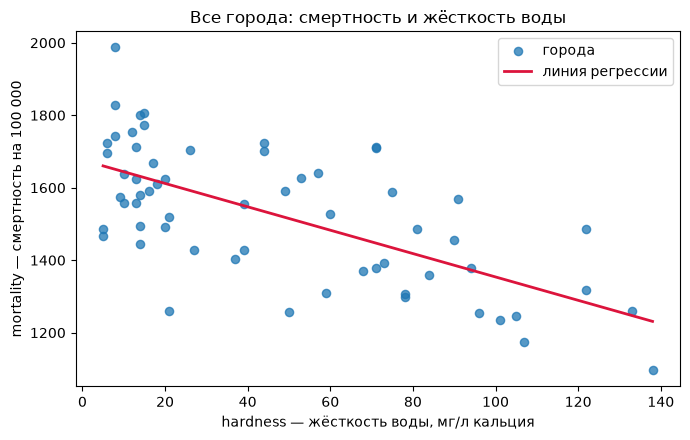

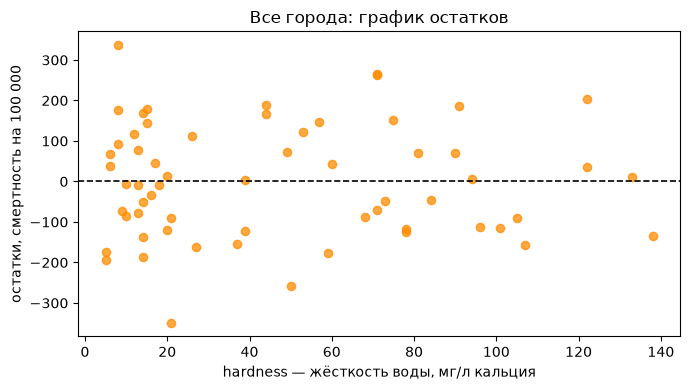

In [3]:
def task_1(file_path):
    data = load_water(file_path)
    print(f"Городов: {len(data)}, из них северных: {(data['location'] == 'North').sum()}, "
          f"южных: {(data['location'] == 'South').sum()}")
    print(f"Смертность: от {data['mortality'].min()} до {data['mortality'].max()}, "
          f"медиана {data['mortality'].median():.0f}")
    print(f"Жёсткость: от {data['hardness'].min()} до {data['hardness'].max()}, "
          f"медиана {data['hardness'].median():.0f}")

    analyze(data, "Все города")


task_1("water.csv")


### Ответ на вопрос 1

**Связь есть, и она обратная.** Коэффициент Пирсона r ≈ −0,65 при p ≈ 1·10⁻⁸ — связь
средней силы, статистически значимая. Спирмен даёт близкое значение (ρ ≈ −0,63), то есть
результат устойчив и не зависит от формы распределения и от отдельных выбросов.

Смысл связи: чем жёстче вода (больше кальция), тем ниже смертность. По линии регрессии
каждые 10 мг/л кальция связаны со снижением смертности примерно на 32 человека на 100 000.

При этом модель объясняет лишь 43 % разброса (R² ≈ 0,43). Значит, жёсткость воды — заметный,
но не единственный фактор: остальные 57 % приходятся на прочие причины.

График остатков: точки рассеяны вокруг нуля без явной структуры, хотя при большой
жёсткости остатки чаще отрицательные — там модель слегка завышает смертность.


## Задание 2. Северные и южные города по отдельности

Делю данные на две группы по столбцу `location` и повторяю для каждой те же шаги.


=== Северные города: n = 35 ===
Пирсон:  r = -0.3686, p = 0.0293
Спирмен: rho = -0.4042, p = 0.016
Регрессия: mortality = 1692.31 -1.9313 * hardness
R^2 = 0.1359 (13.6 % разброса объяснено)
Остатки: min -221.3, max 310.1, стандартное отклонение 127.3


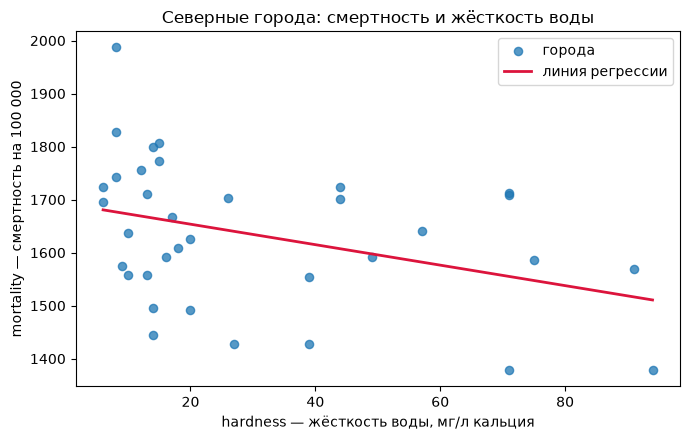

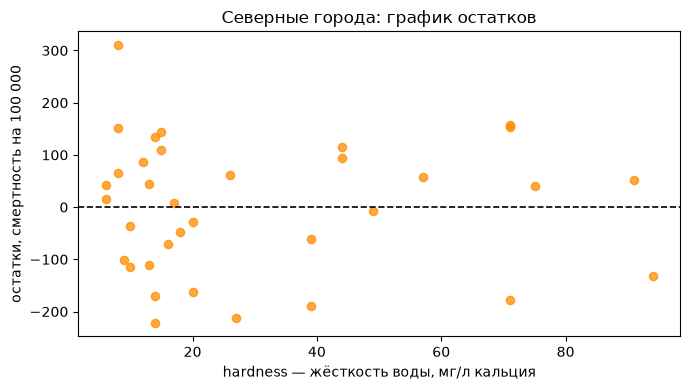


=== Южные города: n = 26 ===
Пирсон:  r = -0.6022, p = 0.00113
Спирмен: rho = -0.5957, p = 0.00132
Регрессия: mortality = 1522.82 -2.0927 * hardness
R^2 = 0.3626 (36.3 % разброса объяснено)
Остатки: min -218.9, max 218.5, стандартное отклонение 112.0


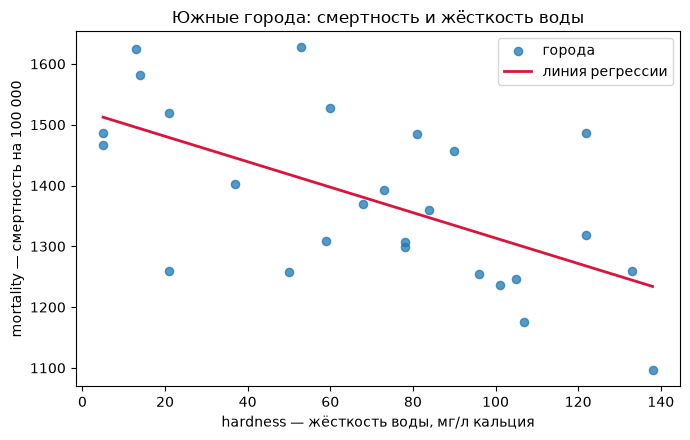

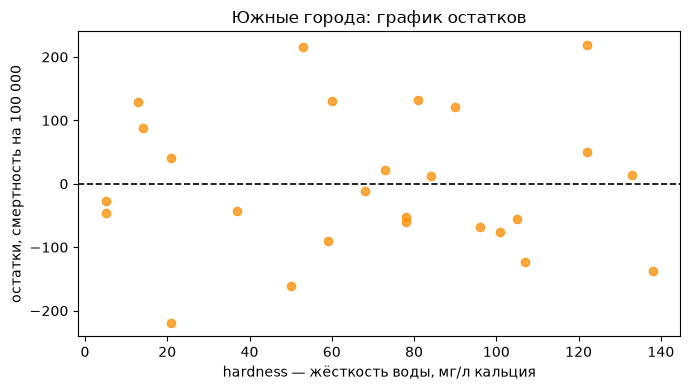

In [4]:
def task_2(file_path):
    data = load_water(file_path)
    for region, name in [("North", "Северные города"), ("South", "Южные города")]:
        analyze(by_region(data, region), name)
        print()


task_2("water.csv")


### Ответ на вопрос 2

**Зависимость сохраняется в обеих группах, но слабеет.** Обратный знак связи остаётся
и у северных, и у южных городов, однако сила различается:

| Группа | n | Пирсон r | Спирмен ρ | R² |
|---|---|---|---|---|
| Все города | 61 | −0,65 | −0,63 | 0,43 |
| Северные | 35 | −0,37 | −0,40 | 0,14 |
| Южные | 26 | −0,60 | −0,60 | 0,36 |

Что это значит:

1. **Связь не исчезла** — ни в одной группе коэффициент не поменял знак и не стал
   нулевым. Но у северных городов она заметно слабее: R² падает с 0,43 до 0,14, то есть
   жёсткость воды объясняет лишь 14 % разброса смертности.
2. **Южные города ведут себя почти как вся выборка** (r ≈ −0,60, R² ≈ 0,36): именно они
   во многом и формируют общую зависимость.
3. **Северные города — главный источник различий.** У них ниже и жёсткость воды (в среднем
   30 против 70 у южных), и разброс смертности объясняется хуже. Здесь сильнее действуют
   другие факторы: плотность населения, промышленность, социальные условия.
4. **Осторожность с причинностью.** Корреляция не доказывает, что жёсткая вода снижает
   смертность. Обе величины могут зависеть от третьего фактора — например, от того,
   насколько город промышленный: в промышленных районах вода мягче, а условия жизни хуже.


In [5]:
def summary_table(file_path):
    """Сводная таблица по всем трём наборам данных."""
    data = load_water(file_path)
    rows = []
    for region, name in [(None, "Все города"), ("North", "Северные"), ("South", "Южные")]:
        subset = by_region(data, region)
        coefficients = correlations(subset)
        model = fit_regression(subset)
        rows.append({
            "группа": name,
            "n": len(subset),
            "Пирсон r": round(coefficients["pearson_r"], 3),
            "p (Пирсон)": f"{coefficients['pearson_p']:.2g}",
            "Спирмен rho": round(coefficients["spearman_rho"], 3),
            "p (Спирмен)": f"{coefficients['spearman_p']:.2g}",
            "наклон": round(model["slope"], 3),
            "R^2": round(determination(model), 3),
        })
    return pd.DataFrame(rows).set_index("группа")


print(summary_table("water.csv").to_string())


             n  Пирсон r p (Пирсон)  Спирмен rho p (Спирмен)  наклон    R^2
группа                                                                     
Все города  61    -0.655      1e-08       -0.632     4.8e-08  -3.226  0.429
Северные    35    -0.369      0.029       -0.404       0.016  -1.931  0.136
Южные       26    -0.602     0.0011       -0.596      0.0013  -2.093  0.363


## Выводы

1. **Связь между жёсткостью воды и смертностью есть.** Она обратная и статистически
   значимая: r Пирсона = −0,65 (p ≈ 10⁻⁸), ρ Спирмена = −0,63. Чем жёстче вода,
   тем ниже смертность.
2. **Связь умеренная, а не определяющая.** R² = 0,43: жёсткостью воды объясняется меньше
   половины разброса смертности.
3. **По группам зависимость сохраняется, но с разной силой.** Северные города: r = −0,37,
   R² = 0,14. Южные: r = −0,60, R² = 0,36. Общая картина формируется в основном южными
   городами.
4. **Корреляция не равна причинности.** Наблюдаемая связь может объясняться третьим
   фактором — социально-экономическими условиями или промышленным характером города.
   Для проверки причинности нужен дизайн исследования, а не наблюдение.


## Самопроверка

* Построен точечный график — да, для всех городов и для каждой группы отдельно.
* Рассчитан коэффициент корреляции Пирсона — да, с p-value.
* Рассчитан коэффициент корреляции Спирмена — да, с p-value.
* Построена модель линейной регрессии — да, методом наименьших квадратов.
* Рассчитан коэффициент детерминации — да, R².
* Выведен график остатков — да, для каждого набора.
* Дан ответ, есть ли взаимосвязь между жёсткостью воды и смертностью — да.
* Шаги 1–6 повторены для северных городов — да.
* Шаги 1–6 повторены для южных городов — да.
* Дан ответ, сохраняется ли зависимость по группам — да.
* Глобальных переменных нет: все данные передаются в функции параметрами — да.
